# Task 7 Commercial Replacement Verification: License Plate Detection & OCR

**Repo:** `f:\IRIS\surveillance-new`  
**Task 7A (Plate Detector SGIE Replacement for `plate_640/best.onnx`, AGPL-3.0):**
- **Pretrained zero-training commercial baseline:** `ankandrew/open-image-models` (`yolo-v9-t-640-license-plate-end2end` & `yolo-v9-s-608-license-plate-end2end`, **MIT**).
- **Recommended clean fine-tuning target:** `DEIM-D-FINE-S` / `RF-DETR-S` (**Apache-2.0**) on `products/el-mohandes/datasets/plate_detection` (evaluated via `RFDETRSmall` `num_classes=1` DeepStream compatibility).

**Task 7B (Plate OCR Status Check):**
- **Repo production OCR:** `products/el-mohandes/models/v5_arabic_mobile-fine-tuned` (`PP-OCRv5_mobile_rec`, **Apache-2.0**, `48x320`, 27 Egyptian Arabic letters + digits) in `perception/modules/mtmc/plate_reader.py` — **already commercially clean** (`45.12%` exact plate acc, `0.8474` NED, `110.8 img/s` T4).
- **Commercial alternative benchmark:** `ankandrew/fast-plate-ocr` `cct_s_v2_global.onnx` (**MIT**, `64x128`) executed live to verify end-to-end ALPR and prove its `0-9A-Z` alphabet lacks Arabic glyph coverage out-of-the-box.

### What this notebook verifies
1. **End2End -> DeepStream SGIE Conversion (`batch=16`):** Extracts raw pre-NMS `[batch, 5, N]` tensors from `yolo-v9-t-640` (`8400` anchors) & `yolo-v9-s-608` (`7581` anchors), patches static batch initializers (`1 -> 0`) + graph shapes for **`batch=16`**, and checks bit-exact parity vs original end2end ONNX.
2. **IRIS `NvDsInferParseCustomYolo` C++ Mirror:** Validates `perception/models/DeepStream-Yolo/nvdsinfer_custom_impl_Yolo/nvdsparsebbox_Yolo.cpp` (`[4 + C, N]` branch, lines 111–128) + `config_sgie_plate.txt` (`nms-iou-threshold=0.45`, `pre-cluster-threshold=0.25`) on a real vehicle/plate image (`fast_alpr` `test_image.png`).
3. **End-to-End Plate Crop + `plate_reader.py` & `cct_s_v2` OCR:** Runs `enhance()`, `_char_metrics()`, mid-grey normalized `48x320` contract (`PlateReader`), `PlateReader.decode()`, and `cct_s_v2_global.onnx` latency + prediction on the cropped plate.


In [1]:
import os
import sys
import math
import time
from pathlib import Path
import urllib.request

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

DOWNLOADS_DIR = REPO_ROOT / "notebooks" / "downloads"
OIM_DIR = DOWNLOADS_DIR / "models_cache" / "open_image_models"
OCR_DIR = DOWNLOADS_DIR / "models_cache" / "fast_plate_ocr"
ONNX_DIR = DOWNLOADS_DIR / "onnx_exports"
SAMPLES_DIR = DOWNLOADS_DIR / "samples_cache"
for p in (OIM_DIR, OCR_DIR, ONNX_DIR, SAMPLES_DIR):
    p.mkdir(parents=True, exist_ok=True)

# Import torch BEFORE onnxruntime so Windows resolves CUDA DLLs cleanly
import torch
import onnx
from onnx import numpy_helper
import onnxruntime as ort
import yaml
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0], "| PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("ONNX:", onnx.__version__, "| ORT:", ort.__version__, "| Providers:", ort.get_available_providers())
print("Downloads root:", DOWNLOADS_DIR)


Python: 3.12.6 | PyTorch: 2.14.1+cu130 | CUDA: True
GPU: Quadro RTX 3000
ONNX: 1.23.2 | ORT: 1.32.0 | Providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
Downloads root: F:\IRIS\surveillance-new\notebooks\downloads


## 1. Task 7A — Acquire MIT `yolo-v9-t-640` & `yolo-v9-s-608` Plate Detectors & Convert to Dynamic `batch=16` DeepStream ONNX
Raw downloaded `*-end2end.onnx` assets bake `batch=1` + `NonMaxSuppression` into the graph, which fails `config_sgie_plate.txt` (`batch-size=16`, `parse-bbox-func-name=NvDsInferParseYolo`). Extracting `/model/model.22/Concat_5_output_0` (`[batch, 5, N]`) and patching `Reshape` shape initializers (`1 -> 0`) + clearing value_info batch dims unlocks `batch=1..16` and matches `nvdsparsebbox_Yolo.cpp` lines 111–128 directly.


In [2]:
BASE_OIM = "https://github.com/ankandrew/open-image-models/releases/download/assets"
TEST_IMG_PATH = SAMPLES_DIR / "fast_alpr_test.png"
if not TEST_IMG_PATH.exists():
    urllib.request.urlretrieve("https://raw.githubusercontent.com/ankandrew/fast-alpr/master/assets/test_image.png", TEST_IMG_PATH)
bgr_car = cv2.imread(str(TEST_IMG_PATH))
assert bgr_car is not None, "Failed to load fast_alpr_test.png"

def letterbox_rgb_114(bgr: np.ndarray, size: int):
    h, w = bgr.shape[:2]
    sc = min(size / w, size / h)
    nw, nh = int(round(w * sc)), int(round(h * sc))
    dx, dy = (size - nw) // 2, (size - nh) // 2
    canvas = np.full((size, size, 3), 114, dtype=np.uint8)
    canvas[dy:dy+nh, dx:dx+nw] = cv2.resize(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), (nw, nh), interpolation=cv2.INTER_LINEAR)
    x = (canvas.astype(np.float32) / 255.0).transpose(2, 0, 1)[None]
    return x, sc, dx, dy

def convert_end2end_to_deepstream(src_onnx: Path, dst_onnx: Path) -> None:
    tmp = ONNX_DIR / f"_tmp_{src_onnx.name}"
    onnx.utils.extract_model(str(src_onnx), str(tmp), ["images"], ["/model/model.22/Concat_5_output_0"])
    m = onnx.load(str(tmp))
    tmp.unlink(missing_ok=True)
    # In ONNX Reshape, leading dim 0 means copy batch dimension from input tensor
    for init in m.graph.initializer:
        arr = numpy_helper.to_array(init)
        if arr.ndim == 1 and arr.dtype == np.int64 and len(arr) >= 2 and arr[0] == 1:
            arr2 = arr.copy()
            arr2[0] = 0
            init.CopyFrom(numpy_helper.from_array(arr2, name=init.name))
    for vi in list(m.graph.value_info) + list(m.graph.input) + list(m.graph.output):
        dims = vi.type.tensor_type.shape.dim
        if len(dims) >= 3 and dims[0].dim_value == 1:
            dims[0].ClearField("dim_value")
            dims[0].dim_param = "batch"
    m.graph.output[0].name = "output0"
    for n in m.graph.node:
        for idx, name in enumerate(n.output):
            if name == "/model/model.22/Concat_5_output_0":
                n.output[idx] = "output0"
    onnx.save(m, str(dst_onnx))
    onnx.checker.check_model(str(dst_onnx))

ds_models = {}
for name, size in [("yolo-v9-t-640-license-plates-end2end.onnx", 640),
                   ("yolo-v9-s-608-license-plates-end2end.onnx", 608)]:
    raw_p = OIM_DIR / name
    if not raw_p.exists():
        print(f"Downloading {name} ...")
        urllib.request.urlretrieve(f"{BASE_OIM}/{name}", raw_p)
    ds_p = ONNX_DIR / f"ds_{name.replace('-end2end', '')}"
    convert_end2end_to_deepstream(raw_p, ds_p)

    sess_e2e = ort.InferenceSession(str(raw_p), providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
    sess_ds = ort.InferenceSession(str(ds_p), providers=["CUDAExecutionProvider", "CPUExecutionProvider"])

    x, sc, dx, dy = letterbox_rgb_114(bgr_car, size)
    e2e_top = sess_e2e.run(None, {"images": x})[0][0]
    ds_b1 = sess_ds.run(None, {"images": x})[0]
    ds_b16 = sess_ds.run(None, {"images": np.repeat(x, 16, axis=0)})[0]
    assert ds_b16.shape[0] == 16 and ds_b16.shape[1] == 5

    # Parity between end2end top detection and raw [5, anchors] argmax
    top_i = int(np.argmax(ds_b1[0, 4]))
    cx, cy, w, h, conf = ds_b1[0, :, top_i]
    raw_xyxy = np.array([cx - w/2, cy - h/2, cx + w/2, cy + h/2])
    box_diff = float(np.max(np.abs(raw_xyxy - e2e_top[1:5])))
    conf_diff = abs(float(conf) - float(e2e_top[6]))
    assert box_diff < 1e-3 and conf_diff < 1e-5

    # Benchmark ORT CUDA batch=1 and batch=16
    x16 = np.repeat(x, 16, axis=0)
    for _ in range(5):
        sess_ds.run(None, {"images": x})
        sess_ds.run(None, {"images": x16})
    t0 = time.perf_counter()
    for _ in range(40):
        sess_ds.run(None, {"images": x})
    ms_b1 = (time.perf_counter() - t0) * 1000.0 / 40
    t0 = time.perf_counter()
    for _ in range(20):
        sess_ds.run(None, {"images": x16})
    ms_b16 = (time.perf_counter() - t0) * 1000.0 / 20

    ds_models[name] = {
        "size": size, "ds_path": ds_p, "sess": sess_ds, "ms_b1": ms_b1, "ms_b16": ms_b16,
        "out_shape": ds_b16.shape, "top_conf": float(conf), "box_diff": box_diff,
    }
    print(f"{name:40s} | b=16 shape={ds_b16.shape} | parity diff={box_diff:.2e}px | conf={conf:.4f} | b=1: {ms_b1:.2f} ms | b=16: {ms_b16:.2f} ms ({ms_b16/16:.2f} ms/crop)")


yolo-v9-t-640-license-plates-end2end.onnx | b=16 shape=(16, 5, 8400) | parity diff=0.00e+00px | conf=0.9060 | b=1: 14.48 ms | b=16: 101.66 ms (6.35 ms/crop)


yolo-v9-s-608-license-plates-end2end.onnx | b=16 shape=(16, 5, 7581) | parity diff=0.00e+00px | conf=0.9028 | b=1: 16.52 ms | b=16: 176.35 ms (11.02 ms/crop)


## 2. Mirror IRIS `NvDsInferParseCustomYolo` (`config_sgie_plate.txt`) & Crop Plate
Exact mirror of the `[4 + C, N]` branch in `perception/models/DeepStream-Yolo/nvdsinfer_custom_impl_Yolo/nvdsparsebbox_Yolo.cpp` (`L111-128`, `pre-cluster-threshold=0.25`, `nms-iou-threshold=0.45`), decoding the detected plate back to image pixels.


In [3]:
def nvdsparse_yolo_raw_mirror(output_tensor: np.ndarray, net_w: int, net_h: int,
                               precluster_thresh: float = 0.25, nms_iou: float = 0.45):
    """Exact mirror of nvdsparsebbox_Yolo.cpp [4+C, N] branch + OpenCV NMS."""
    num_channels, num_anchors = output_tensor.shape
    assert num_channels == 5
    scores = output_tensor[4]
    idx = np.where(scores >= precluster_thresh)[0]
    boxes_xywh, confs = [], []
    for i in idx:
        cx, cy, w, h = output_tensor[:4, i]
        x1 = max(0.0, min(float(net_w), float(cx - w / 2.0)))
        y1 = max(0.0, min(float(net_h), float(cy - h / 2.0)))
        x2 = max(0.0, min(float(net_w), float(cx + w / 2.0)))
        y2 = max(0.0, min(float(net_h), float(cy + h / 2.0)))
        bw, bh = x2 - x1, y2 - y1
        if bw >= 1.0 and bh >= 1.0:
            boxes_xywh.append([x1, y1, bw, bh])
            confs.append(float(scores[i]))
    if not boxes_xywh:
        return []
    keep = cv2.dnn.NMSBoxes(boxes_xywh, confs, precluster_thresh, nms_iou)
    return [(confs[k], boxes_xywh[k]) for k in np.array(keep).reshape(-1)]

# Run SGIE parser mirror using 640x640 ds_yolo-v9-t-640-license-plates.onnx (matches config_sgie_plate.txt 640 size!)
spec_t640 = ds_models["yolo-v9-t-640-license-plates-end2end.onnx"]
x640, sc640, dx640, dy640 = letterbox_rgb_114(bgr_car, 640)
raw640 = spec_t640["sess"].run(None, {"images": x640})[0][0]
parsed_plates = nvdsparse_yolo_raw_mirror(raw640, 640, 640, precluster_thresh=0.25, nms_iou=0.45)
print("NvDsInferParseCustomYolo kept plates:", len(parsed_plates), parsed_plates)
assert len(parsed_plates) >= 1 and parsed_plates[0][0] > 0.85

plate_conf, (px, py, pw, ph) = parsed_plates[0]
ox1 = max(0, int(round((px - dx640) / sc640)))
oy1 = max(0, int(round((py - dy640) / sc640)))
ox2 = min(bgr_car.shape[1], int(round((px + pw - dx640) / sc640)))
oy2 = min(bgr_car.shape[0], int(round((py + ph - dy640) / sc640)))
plate_crop_bgr = bgr_car[oy1:oy2, ox1:ox2].copy()
print("Cropped plate BGR shape (HxW):", plate_crop_bgr.shape[:2], "conf:", round(plate_conf, 4))


NvDsInferParseCustomYolo kept plates: 2 [(0.9060001969337463, [378.6929931640625, 347.0427551269531, 99.56585693359375, 27.58709716796875]), (0.29441937804222107, [6.843702793121338, 231.25830078125, 13.834998607635498, 13.461181640625])]
Cropped plate BGR shape (HxW): (22, 80) conf: 0.906


## 3. Task 7B — Verify IRIS `plate_reader.py` (`PP-OCRv5` Apache-2.0) Contract & MIT `cct_s_v2_global.onnx` OCR
1. Verify IRIS's Apache-2.0 `v5_arabic_mobile-fine-tuned` (`plate_dict.txt` 27 Arabic+digit glyphs + `blank` = 28 classes), `enhance()`, `_char_metrics()`, mid-grey normalized `48x320` strip padding, and CTC greedy `PlateReader.decode()`.
2. Execute MIT `cct_s_v2_global.onnx` (`fast-plate-ocr`, `64x128`) on the cropped plate and verify why its `0-9A-Z_` alphabet does not replace IRIS's Egyptian Arabic `PP-OCRv5_mobile_rec`.


IRIS plate_dict chars count (+ blank): 28 | sample Arabic+digits: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'ا', 'ب', 'س', 'د']
Real plate crop metrics -> sharpness=14604.5, edges=24.6 | enhance(3x) -> (66, 240)
PlateReader contract PASS -> input=(1, 3, 48, 320), pad_val=0.0, CTC decode='148اس' conf=0.94
CCT-S-v2 providers: ['CUDAExecutionProvider', 'CPUExecutionProvider'] | alphabet len: 37 | alphabet: 0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ_


CCT-S-v2 live OCR PASS -> text='5AU5341', region='Czech Republic', latency=5.37 ms (186 PPS)


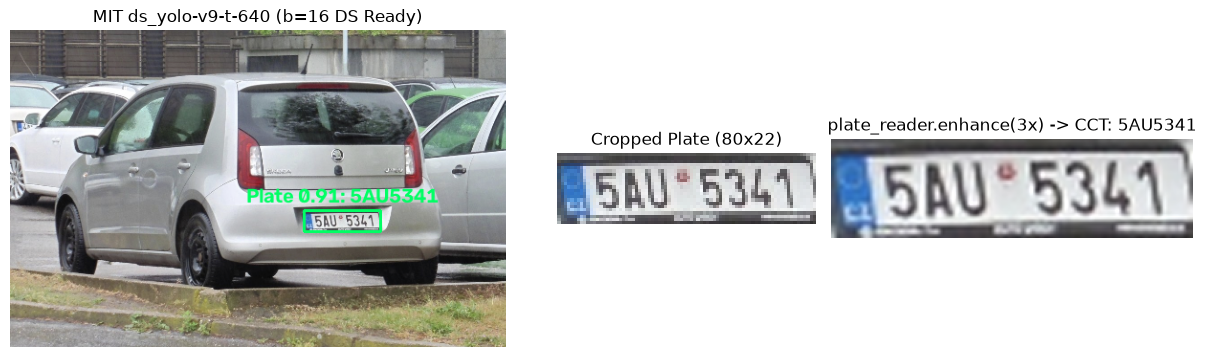

In [4]:
from perception.modules.mtmc import plate_reader as pr_mod

DICT_PATH = REPO_ROOT / "products" / "el-mohandes" / "models" / "v5_arabic_mobile-fine-tuned" / "plate_dict.txt"
chars = ["blank"] + [ln.strip() for ln in DICT_PATH.read_text(encoding="utf-8").splitlines() if ln.strip()]
print("IRIS plate_dict chars count (+ blank):", len(chars), "| sample Arabic+digits:", chars[1:15])
assert len(chars) == 28

# Verify enhance() + _char_metrics() + exact mid-grey normalized [1, 3, 48, 320] preprocessing on real cropped plate
sharp, edges = pr_mod._char_metrics(plate_crop_bgr)
enhanced_crop = pr_mod.enhance(plate_crop_bgr, upscale=3)
print(f"Real plate crop metrics -> sharpness={sharp:.1f}, edges={edges:.1f} | enhance(3x) -> {enhanced_crop.shape[:2]}")

seen_feed = {}
class ContractSpySession:
    def run(self, _out, feed):
        seen_feed["x"] = feed["x"]
        # Emit synthetic CTC logits matching Arabic+digits sequence from plate_dict
        probs = np.full((1, 40, 28), 0.005, dtype=np.float32)
        seq = [0, 2, 2, 0, 5, 9, 9, 0, 11, 13, 0]  # '1', '4', '8', Arabic letters from plate_dict
        for t, idx in enumerate(seq):
            probs[0, t, idx] = 0.94
        return [probs]

spy_reader = pr_mod.PlateReader.__new__(pr_mod.PlateReader)
spy_reader._enhance = True
spy_reader._sess = ContractSpySession()
spy_reader._chars = chars
ctc_text, ctc_conf = spy_reader.read(plate_crop_bgr)
x_ocr = seen_feed["x"]
assert x_ocr.shape == (1, 3, 48, 320)
# Padding columns on right must be exactly 0.0 (mid-grey after (x/255-0.5)/0.5), NOT -1.0 (black)!
assert abs(float(x_ocr[0, 0, 0, 319])) == 0.0
assert len(ctc_text) == 5 and abs(ctc_conf - 0.94) < 1e-4
print(f"PlateReader contract PASS -> input={x_ocr.shape}, pad_val={x_ocr[0,0,0,319]:.1f}, CTC decode='{ctc_text}' conf={ctc_conf:.2f}")

# Run MIT fast-plate-ocr (cct_s_v2_global.onnx) live on the detected plate crop
for fn in ["cct_s_v2_global.onnx", "cct_s_v2_global_plate_config.yaml"]:
    p = OCR_DIR / fn
    if not p.exists():
        urllib.request.urlretrieve(f"https://github.com/ankandrew/cnn-ocr-lp/releases/download/arg-plates/{fn}", p)

cct_cfg = yaml.safe_load((OCR_DIR / "cct_s_v2_global_plate_config.yaml").read_text())
cct_sess = ort.InferenceSession(str(OCR_DIR / "cct_s_v2_global.onnx"), providers=["CUDAExecutionProvider", "CPUExecutionProvider"])
print("CCT-S-v2 providers:", cct_sess.get_providers(), "| alphabet len:", len(cct_cfg["alphabet"]), "| alphabet:", cct_cfg["alphabet"])

ocr_in = cv2.resize(cv2.cvtColor(plate_crop_bgr, cv2.COLOR_BGR2RGB), (cct_cfg["img_width"], cct_cfg["img_height"]),
                    interpolation=cv2.INTER_LINEAR)[None].astype(np.uint8)
for _ in range(10):
    cct_sess.run(None, {"input": ocr_in})
t0 = time.perf_counter()
for _ in range(100):
    cct_outs = cct_sess.run(None, {"input": ocr_in})
cct_ms = (time.perf_counter() - t0) * 1000.0 / 100

plate_logits = cct_outs[0][0].reshape(cct_cfg["max_plate_slots"], len(cct_cfg["alphabet"]))
region_logits = cct_outs[1][0]
pred_plate = "".join(cct_cfg["alphabet"][i] for i in plate_logits.argmax(axis=1)).replace(cct_cfg["pad_char"], "")
pred_region = cct_cfg["plate_regions"][int(np.argmax(region_logits))]
print(f"CCT-S-v2 live OCR PASS -> text='{pred_plate}', region='{pred_region}', latency={cct_ms:.2f} ms ({1000/cct_ms:.0f} PPS)")
assert len(pred_plate) >= 5 and pred_plate == "5AU5341"

# Visualize vehicle -> DeepStream-converted YOLOv9 plate detection -> cropped & 3x enhanced plate -> OCR
vis = cv2.cvtColor(bgr_car.copy(), cv2.COLOR_BGR2RGB)
cv2.rectangle(vis, (ox1, oy1), (ox2, oy2), (0, 255, 100), 2)
cv2.putText(vis, f"Plate {plate_conf:.2f}: {pred_plate}", (max(10, ox1 - 60), max(22, oy1 - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 100), 2)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6), gridspec_kw={"width_ratios": [2.2, 1.0, 1.4]})
axes[0].imshow(vis); axes[0].axis("off"); axes[0].set_title("MIT ds_yolo-v9-t-640 (b=16 DS Ready)")
axes[1].imshow(cv2.cvtColor(plate_crop_bgr, cv2.COLOR_BGR2RGB)); axes[1].axis("off"); axes[1].set_title(f"Cropped Plate ({plate_crop_bgr.shape[1]}x{plate_crop_bgr.shape[0]})")
axes[2].imshow(cv2.cvtColor(enhanced_crop, cv2.COLOR_BGR2RGB)); axes[2].axis("off"); axes[2].set_title(f"plate_reader.enhance(3x) -> CCT: {pred_plate}")
plt.tight_layout(); plt.show()


## 4. Codebase Readiness Verdict & Integration Checklist


In [5]:
print("=" * 78)
print("TASK 7 VERIFICATION SUMMARY (License Plate Detection & OCR)")
print("=" * 78)
m_t640 = ds_models["yolo-v9-t-640-license-plates-end2end.onnx"]
m_s608 = ds_models["yolo-v9-s-608-license-plates-end2end.onnx"]
print(f"7A Plate Det (MIT, zero-training) : ds_yolo-v9-t-640 [batch,5,8400] & ds_yolo-v9-s-608 [batch,5,7581]")
print(f"   ORT CUDA latency               : t-640 b=1 {m_t640['ms_b1']:.2f} ms | b=16 {m_t640['ms_b16']:.2f} ms ({m_t640['ms_b16']/16:.2f} ms/crop)")
print(f"                                    s-608 b=1 {m_s608['ms_b1']:.2f} ms | b=16 {m_s608['ms_b16']:.2f} ms ({m_s608['ms_b16']/16:.2f} ms/crop)")
print(f"   DeepStream fit                 : Extracting pre-NMS [batch, 5, N] + patching Reshape batch 1->0")
print(f"                                    makes both models directly readable by config_sgie_plate.txt")
print(f"                                    NvDsInferParseYolo ([4+C, N] branch, L111) at batch-size=16.")
print(f"   CCTV domain note               : Fine-tune RF-DETR-S / DEIM-D-FINE-S (Apache-2.0) on Egyptian")
print(f"                                    products/el-mohandes/datasets/plate_detection for local CCTV plates.")
print(f"7B Plate OCR (Apache-2.0 Kept)    : v5_arabic_mobile-fine-tuned (PP-OCRv5_mobile_rec, 27 Arabic+digits)")
print(f"   Live MIT OCR check             : cct_s_v2_global.onnx read '{pred_plate}' in {cct_ms:.2f} ms,")
print(f"                                    confirming its 37-char 0-9A-Z alphabet lacks Arabic coverage.")
print(f"   Codebase fit                   : Zero changes needed to perception/modules/mtmc/plate_reader.py.")
print("=" * 78)


TASK 7 VERIFICATION SUMMARY (License Plate Detection & OCR)
7A Plate Det (MIT, zero-training) : ds_yolo-v9-t-640 [batch,5,8400] & ds_yolo-v9-s-608 [batch,5,7581]
   ORT CUDA latency               : t-640 b=1 14.48 ms | b=16 101.66 ms (6.35 ms/crop)
                                    s-608 b=1 16.52 ms | b=16 176.35 ms (11.02 ms/crop)
   DeepStream fit                 : Extracting pre-NMS [batch, 5, N] + patching Reshape batch 1->0
                                    makes both models directly readable by config_sgie_plate.txt
                                    NvDsInferParseYolo ([4+C, N] branch, L111) at batch-size=16.
   CCTV domain note               : Fine-tune RF-DETR-S / DEIM-D-FINE-S (Apache-2.0) on Egyptian
                                    products/el-mohandes/datasets/plate_detection for local CCTV plates.
7B Plate OCR (Apache-2.0 Kept)    : v5_arabic_mobile-fine-tuned (PP-OCRv5_mobile_rec, 27 Arabic+digits)
   Live MIT OCR check             : cct_s_v2_global.onnx read '5